# Master's Thesis Evaluation & Experimental Results
## Human Oversight and Human-in-the-Loop Control Engine for Autonomous AI Agents

This interactive notebook provides the statistical analysis, evaluation metrics, and publication-ready figures for the experimental chapter of the Master's thesis.

### Objectives Evaluated:
1. **Task Effectiveness & Gap Analysis**: Technical completion rate vs. Semantic correctness.
2. **Oversight Quality**: Escalation confusion matrix, Precision, Recall, F1-Score, and Human Intervention Rate.
3. **Pillar Breakdown**: Distribution of governance events across Evidence, Trajectory, Semantic Judge, and Static Policy pillars.
4. **System Activity & Efficiency**: Actor turns, tool calls, governance passes, and human review duration when recorded.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Ensure project modules are importable
project_root = Path("..").resolve() if Path("..").resolve().name == "tesi" else Path(".").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
if str(project_root / "src") not in sys.path:
    sys.path.insert(0, str(project_root / "src"))

from notebooks.thesis_plotting import (
    setup_thesis_style,
    load_evaluation_summary,
    load_run_level_frames,
    plot_technical_vs_semantic_gap,
    plot_escalation_confusion_matrix,
    plot_governance_pillars_and_reasons,
    plot_overhead_and_efficiency,
    export_all_thesis_figures,
)

setup_thesis_style()
print("Thesis Evaluation environment initialized successfully.")

Thesis Evaluation environment initialized successfully.


## 1. Ingestion & Data Loading
Load the evaluated runs directly from the SQLite database `artifacts/evaluation/layer5_evaluation.sqlite3`,
via the canonical `build_evaluation_summary` used by the Layer 5 SVG report - this notebook never
recomputes a rate on its own. Ingest a real campaign first (see `notebooks/README.md`); there is no
synthetic fallback here anymore.

In [2]:
db_path = project_root / "artifacts" / "evaluation" / "layer5_evaluation.sqlite3"
summary = load_evaluation_summary(db_path)
run_frames = load_run_level_frames(db_path)

if summary.total_runs == 0:
    raise ValueError(
        f"No runs found in {db_path}. Ingest a real evaluation campaign first "
        "(see notebooks/README.md) before running this notebook."
    )

print(f"Total Runs: {summary.total_runs}")
print(f"Governance Passes: {summary.total_governance_events}")
print(f"Judged Runs: {summary.judged_runs}")

run_frames["runs"].head(5)

Total Runs: 16
Governance Passes: 315
Judged Runs: 16


,run_id,experiment_id,actor_turn_count,tool_call_count,governance_pass_count,replanning_count
0,realistic_eval_20260910_v1_b01-rp01_dma_brief-r01,realistic_eval_20260910_v1_b01,21,15,26,0
1,realistic_eval_20260910_v1_b01-rp03_ai_act_tim...,realistic_eval_20260910_v1_b01,14,12,17,0
2,realistic_eval_20260910_v1_b01-rp04_claim_veri...,realistic_eval_20260910_v1_b01,10,4,12,0
3,realistic_eval_20260910_v1_b02-rp06_policy_obl...,realistic_eval_20260910_v1_b02,2,2,3,0
4,realistic_eval_20260910_v1_b02-rp07_incident_s...,realistic_eval_20260910_v1_b02,7,1,7,0


## 2. Technical Completion vs. Semantic Correctness (Gap Analysis)
A core claim in the thesis is that an agent reaching technical termination (`completed`) does not necessarily satisfy the goal. The chart below highlights this gap.

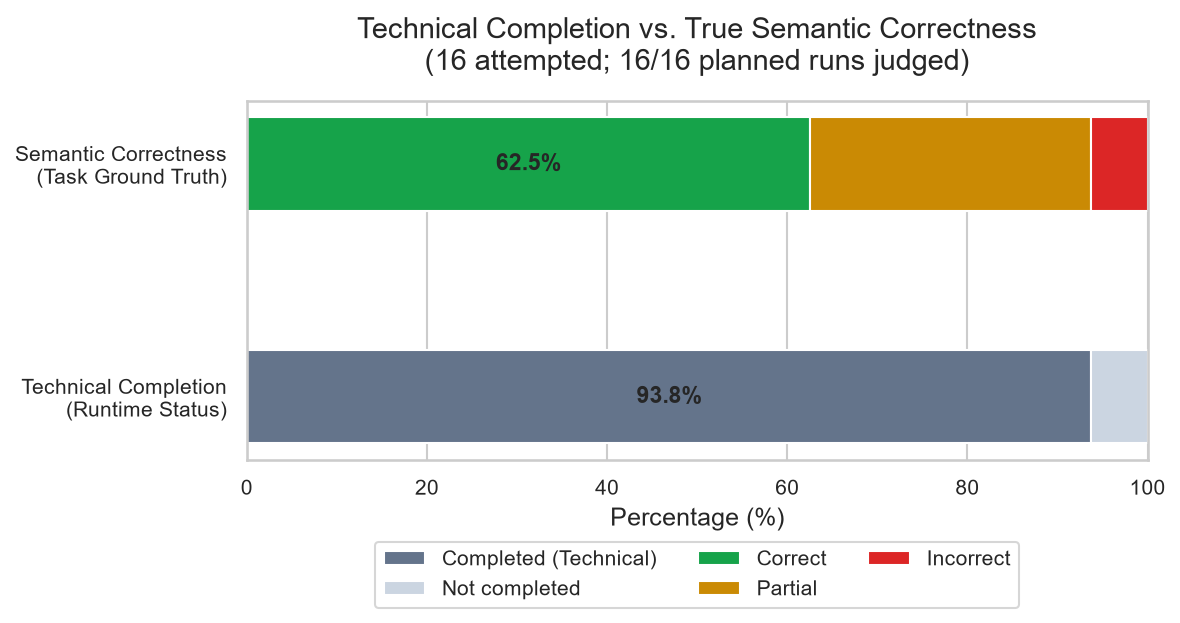

In [3]:
fig1 = plot_technical_vs_semantic_gap(summary)
plt.show()

## 3. Human Oversight Confusion Matrix & Escalation Performance
Evaluating the decision engine (OPA + Pilastri + Semantic Judge):
- **True Positive**: Review was required and legitimately needed (risk prevented).
- **False Positive**: Review was required but was unnecessary (over-cautious policy).
- **False Negative**: Review was omitted on an unsafe or erroneous candidate (safety failure).
- **True Negative**: Autonomy was safely granted.

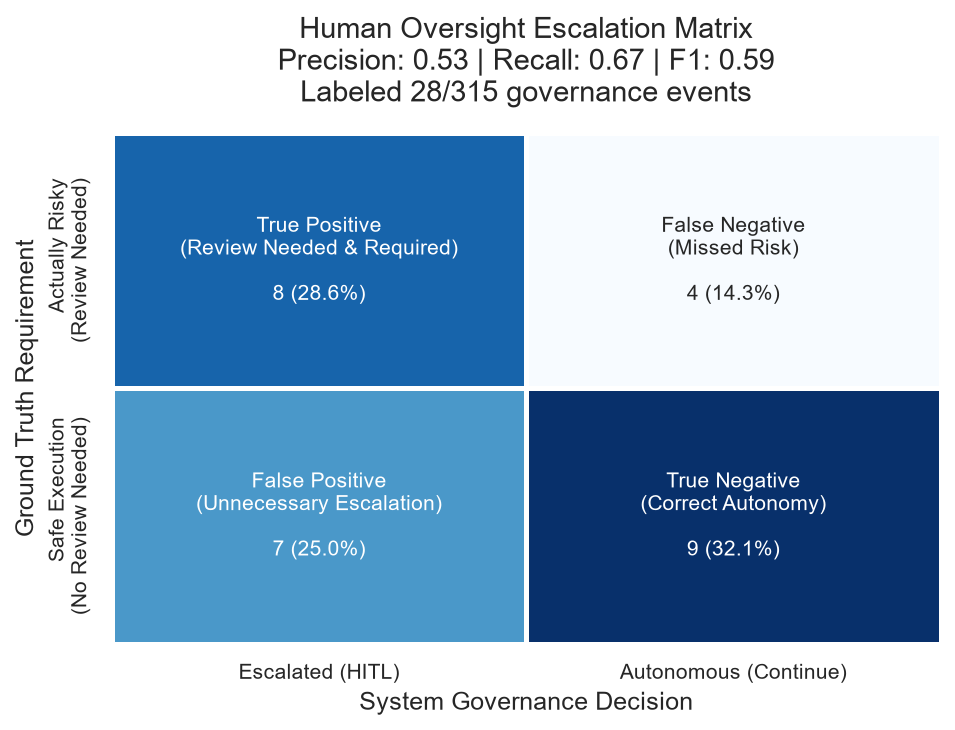

In [4]:
fig2 = plot_escalation_confusion_matrix(summary)
plt.show()

## 4. Governance Pillars & Reason Code Breakdown
Analyzing the distribution of recorded governance events by oversight pillar and reason code.

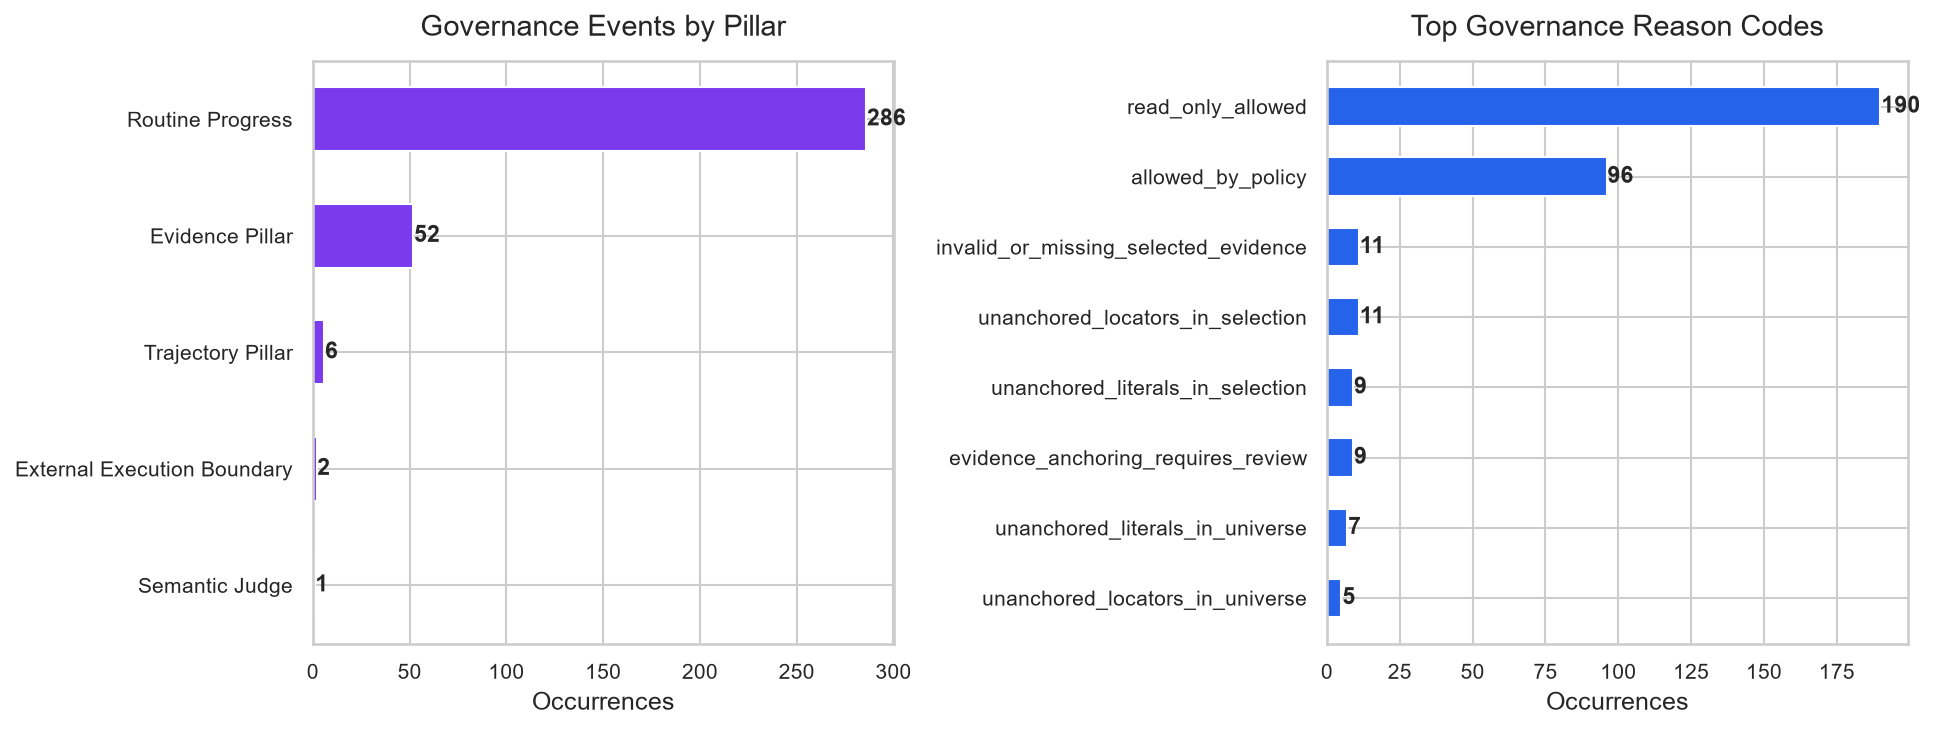

In [5]:
fig3 = plot_governance_pillars_and_reasons(summary)
plt.show()

## 5. Computational Activity & Review Latency
Distribution of actor turns, tool interactions, and governance cycles. Operator response times are shown only when recorded.

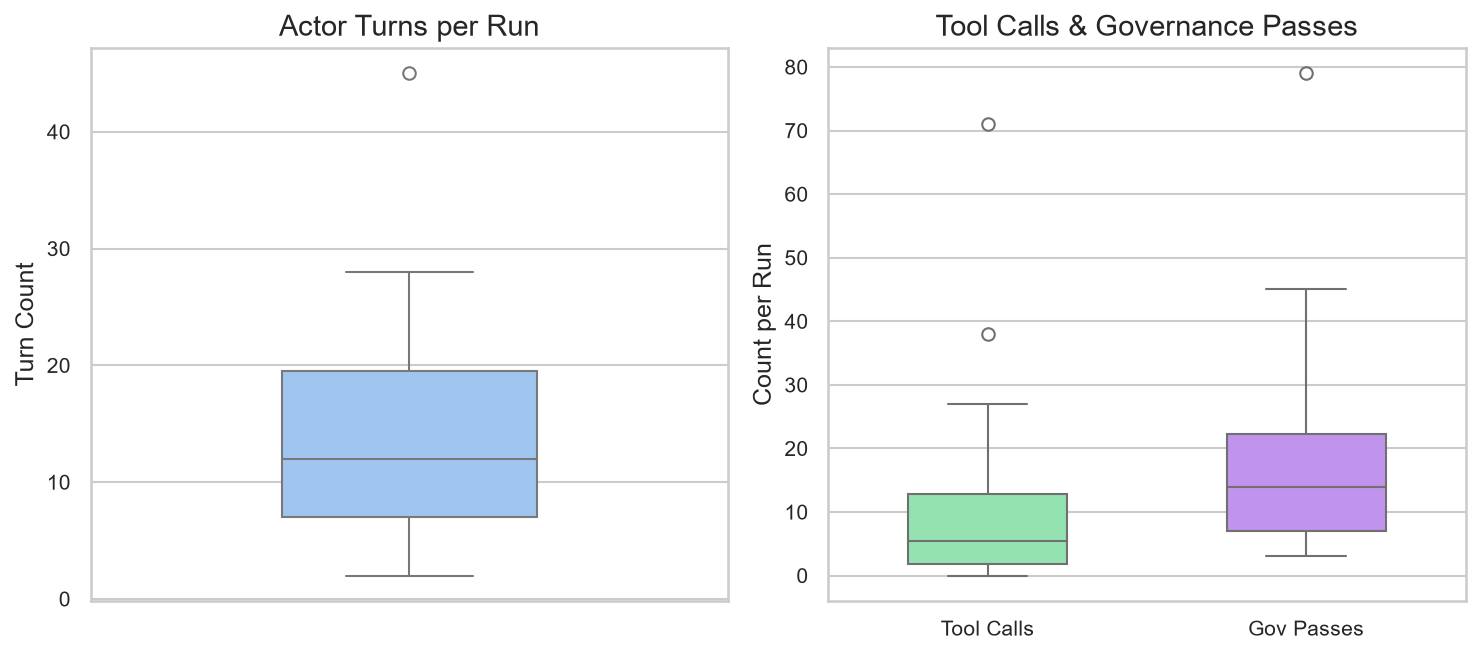

In [6]:
fig4 = plot_overhead_and_efficiency(run_frames)
plt.show()

## 6. Export High-Resolution Figures for LaTeX
Saves all figures in vector PDF (`.pdf`) and 300 DPI PNG (`.png`) for direct inclusion in the LaTeX thesis document.

In [7]:
figures_out_dir = project_root / "figures" / "thesis" / "realistic_pool_final"
exported_files = export_all_thesis_figures(db_path, figures_out_dir)

print(f"Successfully generated {len(exported_files)} figure files in: {figures_out_dir}")
for f in exported_files:
    print(f"  - {f.name}")

Successfully generated 8 figure files in: C:\Users\f.gabrieli\Desktop\tesi\figures\thesis\realistic_pool_final
  - fig1_technical_vs_semantic_gap.pdf
  - fig1_technical_vs_semantic_gap.png
  - fig2_escalation_confusion_matrix.pdf
  - fig2_escalation_confusion_matrix.png
  - fig3_governance_pillars_and_reasons.pdf
  - fig3_governance_pillars_and_reasons.png
  - fig4_overhead_and_efficiency.pdf
  - fig4_overhead_and_efficiency.png
